Mount Google Drive

In [32]:
import os, glob
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Auto-find your CSV inside Google Drive and set that folder as working directory
matches = glob.glob('/content/drive/MyDrive/**/ai_ds_job_salaries_2026_5000x16*.csv', recursive=True)

if matches:
    DATASET_PATH = matches[0]
    PROJECT_DIR = os.path.dirname(DATASET_PATH)
    os.chdir(PROJECT_DIR)
    print("Project Folder:", PROJECT_DIR)
    print("Dataset Found:", os.path.basename(DATASET_PATH))
else:
    # Fallback: manually paste your folder path below if needed
    PROJECT_DIR = '/content/drive/MyDrive/YOUR_FOLDER_NAME'
    os.chdir(PROJECT_DIR)
    DATASET_PATH = 'ai_ds_job_salaries_2026_5000x16_2.csv'
    print("Using manual folder:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Folder: /content/drive/MyDrive/DS1
Dataset Found: ai_ds_job_salaries_2026_5000x16.csv


Import Libraries

In [33]:
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Machine Learning Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# Model evaluation (Regression Metrics)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [34]:
# Load the dataset from your Drive folder
data = pd.read_csv(os.path.basename(DATASET_PATH))
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [35]:
# Preview the dataset
data.head(10)

,job_title,experience_level,employment_type,company_size,company_location,industry,remote_ratio,years_experience,education_level,primary_language,manages_people,certifications_count,weekly_hours,ai_tools_hours_per_week,job_satisfaction_score,salary_usd
0,Data Analyst,Lead,Part-time,S,IN,Finance,0,14.4,Bachelors,Python,True,0,48.0,12.5,5.5,23844
1,Research Scientist,Senior,Full-time,L,US,Retail,50,7.6,Masters,SQL,False,1,41.6,2.1,7.0,170132
2,Machine Learning Engineer,Entry,Full-time,M,US,Government,0,0.0,Bootcamp,Python,False,1,55.1,5.1,5.9,83059
3,Data Engineer,Senior,Full-time,M,BR,Government,100,9.7,Masters,Java,False,2,41.1,2.0,5.6,29531
4,Data Engineer,Mid,Full-time,M,US,Education,0,3.2,Bachelors,Python,False,2,48.2,4.0,4.6,70105
5,Analytics Engineer,Senior,Full-time,M,SG,Finance,100,11.6,Masters,Python,False,1,54.6,17.4,7.9,97827
6,Business Intelligence Analyst,Senior,Full-time,M,US,Technology,0,9.8,Bachelors,Python,False,1,48.4,0.5,5.5,120062
7,Data Analyst,Entry,Full-time,M,US,Retail,0,1.4,Masters,Python,False,3,49.8,4.2,7.3,64165
8,Research Scientist,Mid,Full-time,M,AU,Finance,0,2.2,Masters,Python,False,3,36.1,6.6,7.7,112968
9,Data Engineer,Entry,Part-time,L,GB,Healthcare,0,2.8,Self-taught,SQL,False,2,44.8,2.0,6.2,26464


In [36]:
# Check the dataset shape
print("Dataset Shape:", data.shape)

Dataset Shape: (5000, 16)


In [37]:
# Dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   job_title                5000 non-null   object 
 1   experience_level         5000 non-null   object 
 2   employment_type          5000 non-null   object 
 3   company_size             5000 non-null   object 
 4   company_location         5000 non-null   object 
 5   industry                 5000 non-null   object 
 6   remote_ratio             5000 non-null   int64  
 7   years_experience         5000 non-null   float64
 8   education_level          5000 non-null   object 
 9   primary_language         5000 non-null   object 
 10  manages_people           5000 non-null   bool   
 11  certifications_count     5000 non-null   int64  
 12  weekly_hours             5000 non-null   float64
 13  ai_tools_hours_per_week  5000 non-null   float64
 14  job_satisfaction_score  

In [38]:
# Statistical description
data.describe()

,remote_ratio,years_experience,certifications_count,weekly_hours,ai_tools_hours_per_week,job_satisfaction_score,salary_usd
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.08000,8.361440,1.820400,44.345400,8.437400,6.685320,98605.406200
std,41.45428,4.820808,1.344212,6.142761,5.503637,1.364302,55369.310473
min,0.00000,0.000000,0.000000,24.400000,0.000000,1.100000,12000.000000
25%,0.00000,4.800000,1.000000,40.100000,3.300000,5.800000,55592.750000
50%,50.00000,8.100000,2.000000,44.400000,8.500000,6.700000,90572.000000
75%,100.00000,11.500000,3.000000,48.500000,12.625000,7.600000,129657.750000
max,100.00000,23.700000,8.000000,67.300000,25.200000,10.000000,372347.000000


Exploratory Data Analysis

In [39]:
# Check column names and data types
print("Column Names:")
print(data.columns.tolist())

print("\nData Types:")
print(data.dtypes)

Column Names:
['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'remote_ratio', 'years_experience', 'education_level', 'primary_language', 'manages_people', 'certifications_count', 'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score', 'salary_usd']

Data Types:
job_title                   object
experience_level            object
employment_type             object
company_size                object
company_location            object
industry                    object
remote_ratio                 int64
years_experience           float64
education_level             object
primary_language            object
manages_people                bool
certifications_count         int64
weekly_hours               float64
ai_tools_hours_per_week    float64
job_satisfaction_score     float64
salary_usd                   int64
dtype: object


In [40]:
# Check unique values
for column in data.columns:
    print(f"\n{column} ({data[column].nunique()} unique):")
    print(data[column].unique()[:10])


job_title (12 unique):
['Data Analyst' 'Research Scientist' 'Machine Learning Engineer'
 'Data Engineer' 'Analytics Engineer' 'Business Intelligence Analyst'
 'Data Science Manager' 'Computer Vision Engineer' 'LLM Engineer'
 'Data Scientist']

experience_level (5 unique):
['Lead' 'Senior' 'Entry' 'Mid' 'Executive']

employment_type (4 unique):
['Part-time' 'Full-time' 'Contract' 'Freelance']

company_size (3 unique):
['S' 'L' 'M']

company_location (12 unique):
['IN' 'US' 'BR' 'SG' 'AU' 'GB' 'FR' 'DE' 'PL' 'NL']

industry (10 unique):
['Finance' 'Retail' 'Government' 'Education' 'Technology' 'Healthcare'
 'Consulting' 'Media' 'Manufacturing' 'Energy']

remote_ratio (3 unique):
[  0  50 100]

years_experience (230 unique):
[14.4  7.6  0.   9.7  3.2 11.6  9.8  1.4  2.2  2.8]

education_level (5 unique):
['Bachelors' 'Masters' 'Bootcamp' 'Self-taught' 'PhD']

primary_language (7 unique):
['Python' 'SQL' 'Java' 'R' 'Julia' 'Scala' 'Rust']

manages_people (2 unique):
[ True False]

certifi

count      5000.000000
mean      98605.406200
std       55369.310473
min       12000.000000
25%       55592.750000
50%       90572.000000
75%      129657.750000
max      372347.000000
Name: salary_usd, dtype: float64


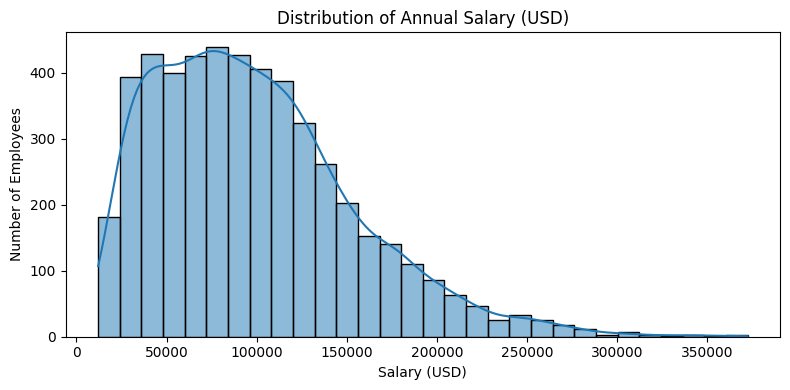

In [41]:
# Checking the target variable distribution (salary_usd)
print(data['salary_usd'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data['salary_usd'], bins=30, kde=True)
plt.title('Distribution of Annual Salary (USD)')
plt.xlabel('Salary (USD)')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.savefig('target_salary_distribution.png', dpi=150)
plt.show()

experience_level
Mid          1613
Senior       1520
Entry         985
Lead          656
Executive     226
Name: count, dtype: int64


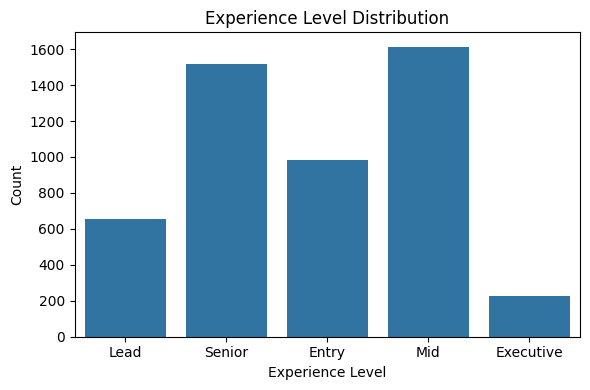

In [42]:
# Analyze Experience Level distribution
print(data['experience_level'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='experience_level')
plt.title('Experience Level Distribution')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('experience_level_distribution.png', dpi=150)
plt.show()

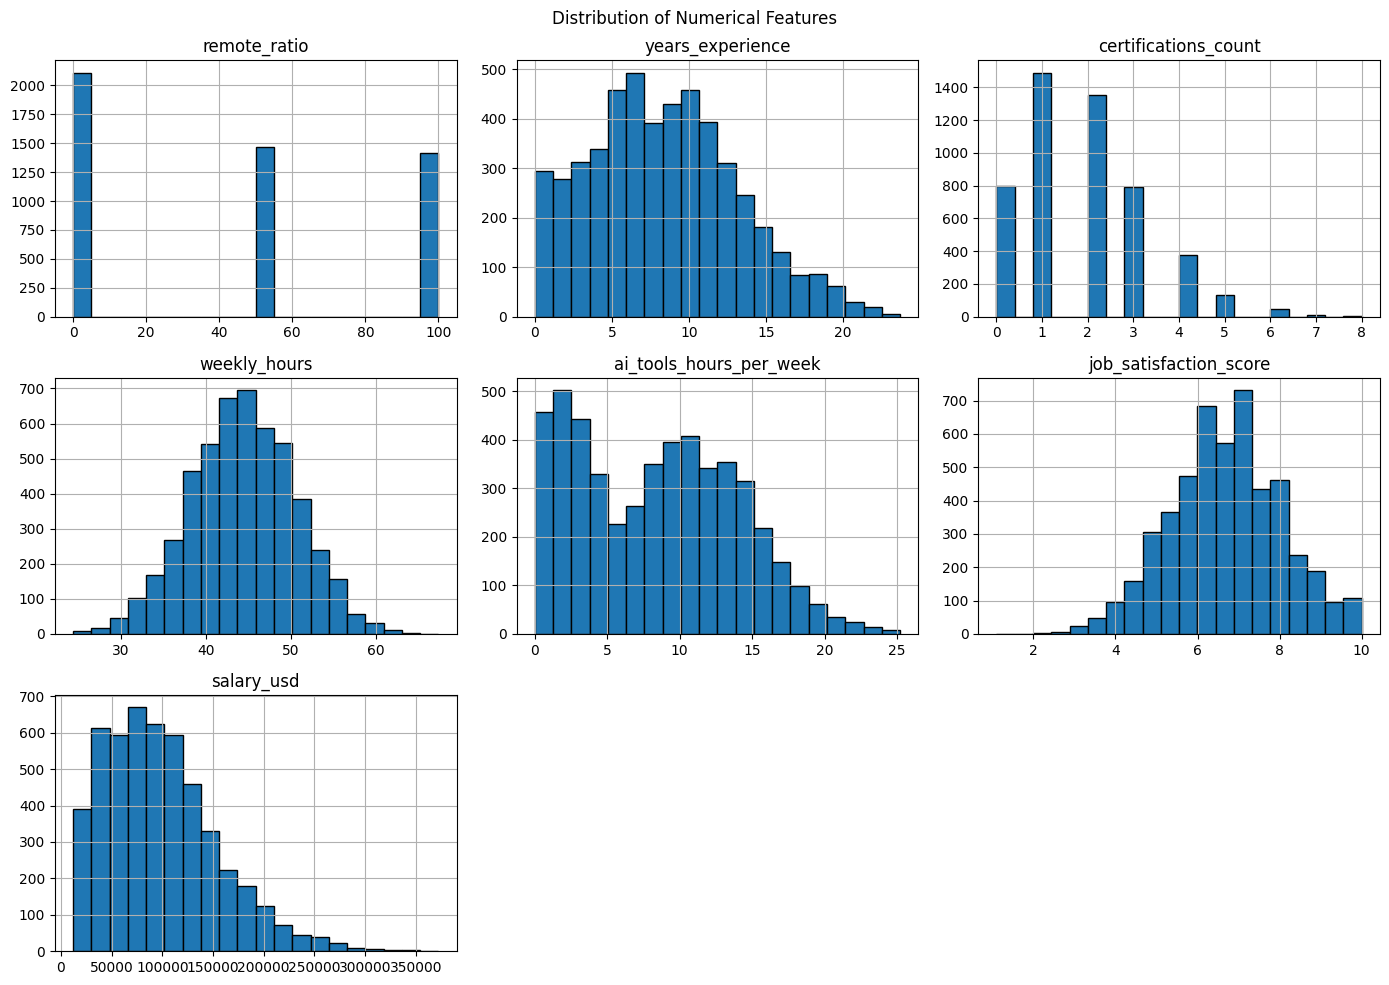

In [43]:
# Analyze numerical feature distributions
numerical_columns = [
    'remote_ratio', 'years_experience', 'certifications_count',
    'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score',
    'salary_usd'
]

data[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.savefig('numerical_distributions.png', dpi=150)
plt.show()

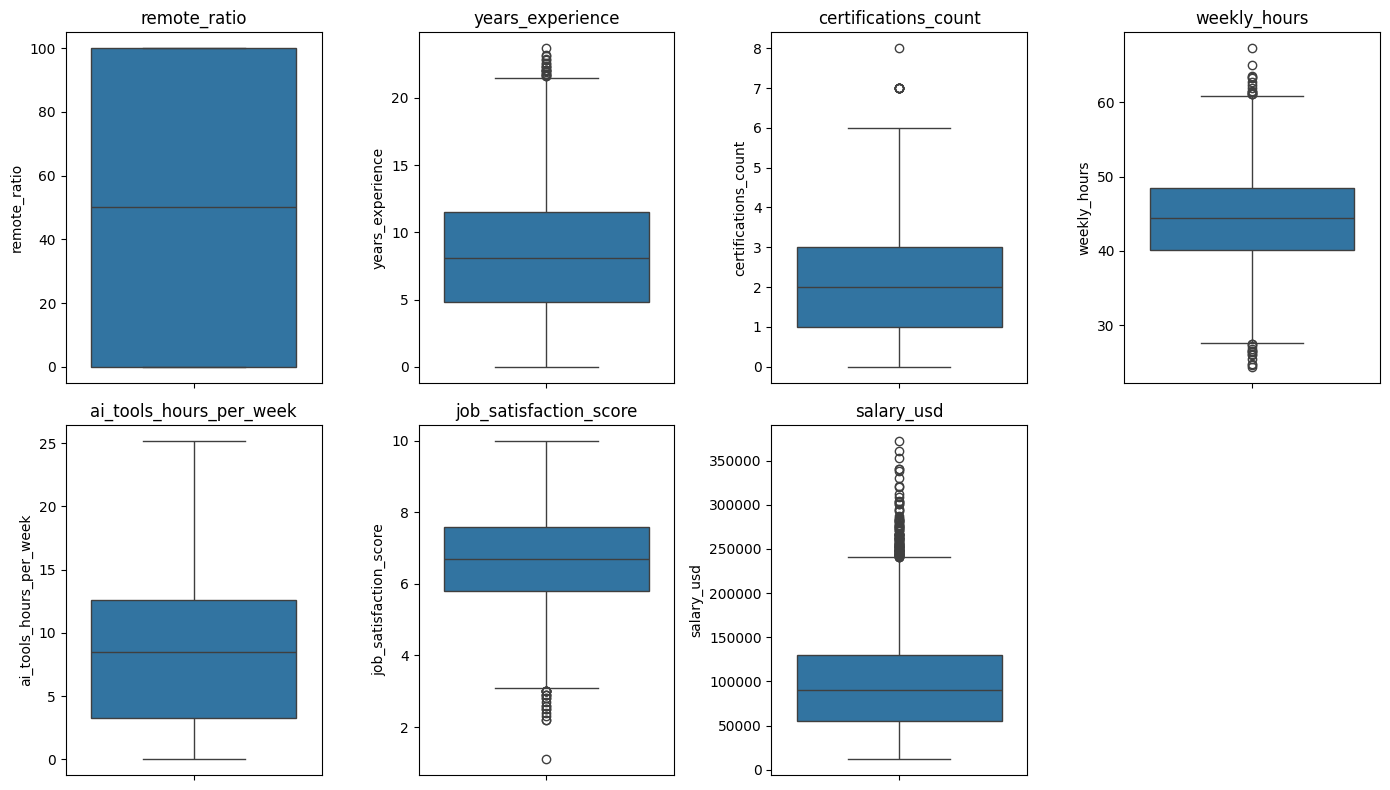

In [44]:
# Boxplots to identify possible outliers
plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=data[column])
    plt.title(column)

plt.tight_layout()
plt.savefig('numerical_boxplots.png', dpi=150)
plt.show()

Data Cleaning

In [45]:
print("Missing Values in Each Column:")
print(data.isnull().sum())

print("\nTotal Missing Values:")
print(data.isnull().sum().sum())

Missing Values in Each Column:
job_title                  0
experience_level           0
employment_type            0
company_size               0
company_location           0
industry                   0
remote_ratio               0
years_experience           0
education_level            0
primary_language           0
manages_people             0
certifications_count       0
weekly_hours               0
ai_tools_hours_per_week    0
job_satisfaction_score     0
salary_usd                 0
dtype: int64

Total Missing Values:
0


In [46]:
print("Number of Duplicate Rows:", data.duplicated().sum())

Number of Duplicate Rows: 0


In [47]:
data = data.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(data.shape)

Dataset Shape After Removing Duplicates:
(5000, 16)


In [48]:
print("Missing Values:", data.isnull().sum().sum())
print("Duplicate Rows:", data.duplicated().sum())
print("Final Dataset Shape:", data.shape)

Missing Values: 0
Duplicate Rows: 0
Final Dataset Shape: (5000, 16)


**Data Preprocessing**

In [49]:
df = data.copy()

print("Original Dataset Shape:", data.shape)
print("Working Dataset Shape:", df.shape)

Original Dataset Shape: (5000, 16)
Working Dataset Shape: (5000, 16)


In [50]:
# Converting categorical values into numerical values (Label Encoding)
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

print("\nUpdated Dataset:")
df.head()

job_title: {'AI Engineer': np.int64(0), 'Analytics Engineer': np.int64(1), 'Business Intelligence Analyst': np.int64(2), 'Computer Vision Engineer': np.int64(3), 'Data Analyst': np.int64(4), 'Data Engineer': np.int64(5), 'Data Science Manager': np.int64(6), 'Data Scientist': np.int64(7), 'LLM Engineer': np.int64(8), 'MLOps Engineer': np.int64(9), 'Machine Learning Engineer': np.int64(10), 'Research Scientist': np.int64(11)}
experience_level: {'Entry': np.int64(0), 'Executive': np.int64(1), 'Lead': np.int64(2), 'Mid': np.int64(3), 'Senior': np.int64(4)}
employment_type: {'Contract': np.int64(0), 'Freelance': np.int64(1), 'Full-time': np.int64(2), 'Part-time': np.int64(3)}
company_size: {'L': np.int64(0), 'M': np.int64(1), 'S': np.int64(2)}
company_location: {'AU': np.int64(0), 'BR': np.int64(1), 'CA': np.int64(2), 'DE': np.int64(3), 'ES': np.int64(4), 'FR': np.int64(5), 'GB': np.int64(6), 'IN': np.int64(7), 'NL': np.int64(8), 'PL': np.int64(9), 'SG': np.int64(10), 'US': np.int64(11)}
in

,job_title,experience_level,employment_type,company_size,company_location,industry,remote_ratio,years_experience,education_level,primary_language,manages_people,certifications_count,weekly_hours,ai_tools_hours_per_week,job_satisfaction_score,salary_usd
0,4,2,3,2,7,3,0,14.4,0,2,1,0,48.0,12.5,5.5,23844
1,11,4,2,0,11,8,50,7.6,2,5,0,1,41.6,2.1,7.0,170132
2,10,0,2,1,11,4,0,0.0,1,2,0,1,55.1,5.1,5.9,83059
3,5,4,2,1,1,4,100,9.7,2,0,0,2,41.1,2.0,5.6,29531
4,5,3,2,1,11,1,0,3.2,0,2,0,2,48.2,4.0,4.6,70105


Separate input features (X) and target variable (y)

In [51]:
X = df.drop('salary_usd', axis=1)
y = df['salary_usd']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (5000, 15)
Target Variable Shape: (5000,)

Input Features:
['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'remote_ratio', 'years_experience', 'education_level', 'primary_language', 'manages_people', 'certifications_count', 'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score']


Split the dataset 80:20

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (4000, 15)
Testing Data Shape: (1000, 15)


Apply StandardScaler

In [53]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data After Scaling:")
print(X_train_scaled[:5])

Training Data After Scaling:
[[ 0.46771153  0.34666773  0.2741884   0.05001148  0.23705866  1.11341597
  -1.04432197 -0.54834441  0.48960982  0.21950999 -0.53997453 -1.35757414
  -0.38851436  0.43122204  1.68780885]
 [-0.43680715 -1.02356045  0.2741884   0.05001148 -1.95983597 -0.51379042
  -1.04432197  2.19983168 -1.10456135 -0.45538622  1.85193921  1.63062042
   1.46269461  0.10309553 -0.66266968]
 [-1.34132583  1.03178182  0.2741884   1.47891101 -1.95983597  1.11341597
   0.15777526  0.55508993  2.083781    0.21950999 -0.53997453 -1.35757414
  -0.07997953  1.08747508  1.68780885]
 [ 0.46771153  1.03178182  0.2741884   0.05001148 -0.312165   -0.8392317
   1.3598725   1.09639734 -1.10456135  2.24419865 -0.53997453  0.88357178
   0.76443157 -1.26409829  0.65947449]
 [ 1.07072399  1.03178182  1.85225116  0.05001148 -0.03755317  0.46253342
   0.15777526  0.47181187 -1.10456135 -0.45538622 -0.53997453  0.13652314
  -0.61585582 -1.02711803 -0.95647949]]


**Train Machine Learning Regression Models**

Train Linear Regression

In [54]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


Train KNN Regressor

In [55]:
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

print("KNN Regressor Training Completed!")

KNN Regressor Training Completed!


Train Random Forest Regressor

In [56]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_scaled, y_train)

print("Random Forest Regressor Training Completed!")

Random Forest Regressor Training Completed!


In [57]:
lr_pred = lr_model.predict(X_test_scaled)
knn_pred = knn_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test_scaled)

print("All predictions completed!")
print("\nLinear Regression Predictions:", np.round(lr_pred[:5], 2))
print("KNN Predictions:", np.round(knn_pred[:5], 2))
print("Random Forest Predictions:", np.round(rf_pred[:5], 2))

All predictions completed!

Linear Regression Predictions: [ 79390.41  70389.37  97048.41 126462.16 112138.32]
KNN Predictions: [ 69121.6  71128.2  50378.6 158039.2 122341. ]
Random Forest Predictions: [35727.34 89179.03 62507.52 47837.16 73850.55]


**Model Evaluation**

In [58]:
def eval_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'R2 Score': r2, 'MAE': mae, 'MSE': mse, 'RMSE': rmse}

results = pd.DataFrame([
    eval_model('Linear Regression', y_test, lr_pred),
    eval_model('KNN Regressor', y_test, knn_pred),
    eval_model('Random Forest Regressor', y_test, rf_pred)
])

print(results.round(4))

# Save results table inside your Drive folder
results.to_csv('model_comparison_results.csv', index=False)
print("\nSaved model_comparison_results.csv in your Drive folder!")

                     Model  R2 Score         MAE           MSE        RMSE
0        Linear Regression    0.3476  34829.9509  1.985057e+09  44553.9757
1            KNN Regressor    0.2989  35372.4866  2.133125e+09  46185.7695
2  Random Forest Regressor    0.7440  19990.6629  7.788536e+08  27907.9479

Saved model_comparison_results.csv in your Drive folder!


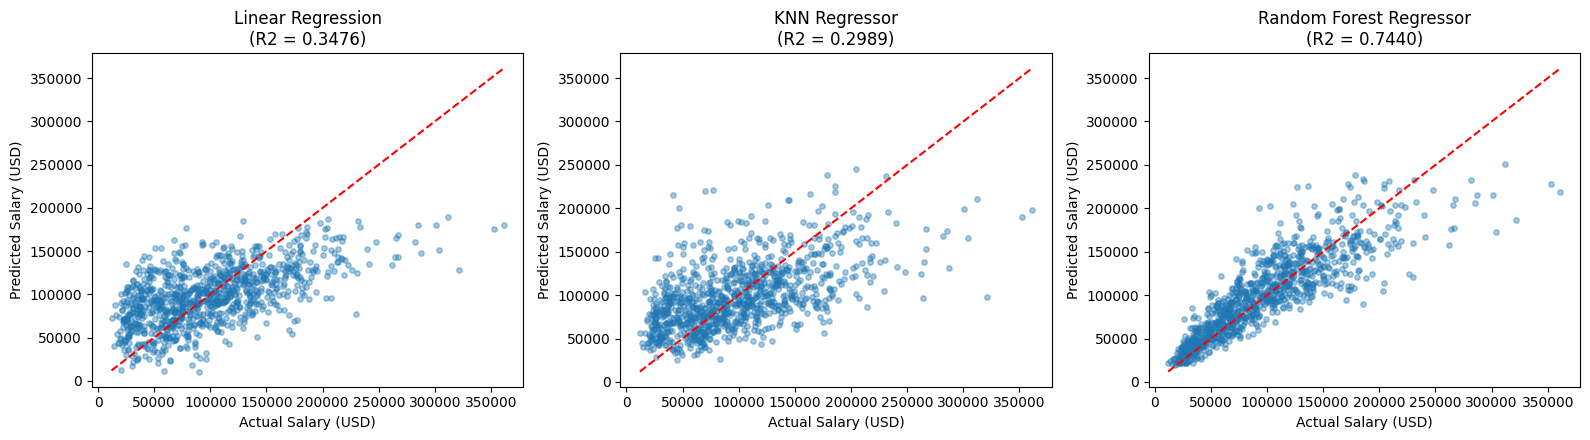

In [59]:
# Visual comparison: Actual vs Predicted Salary
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
preds = [
    ('Linear Regression', lr_pred),
    ('KNN Regressor', knn_pred),
    ('Random Forest Regressor', rf_pred)
]

for ax, (title, pred) in zip(axes, preds):
    ax.scatter(y_test, pred, alpha=0.4, s=15)
    min_val, max_val = y_test.min(), y_test.max()
    ax.plot([min_val, max_val], [min_val, max_val], 'r--')
    ax.set_title(f'{title}\n(R2 = {r2_score(y_test, pred):.4f})')
    ax.set_xlabel('Actual Salary (USD)')
    ax.set_ylabel('Predicted Salary (USD)')

plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150)
plt.show()